# 02 — Native Zeek Hybrid Model (`zeek-hybrid-m3-v1`)

**How the 19 Hybrid features work** (implemented in `src/cybershield/ml/zeek_features.py`):
1. **Tumbling 60s buckets:** Assign every Zeek `conn.log` row `window_id = int(ts // 60)`.
2. **Group by `(src_ip, window_id)`** to compute 5 host-behavior stats: `host_conn_60s`, `host_uniq_ports_60s`, `host_failed_ratio_60s`, `host_orig_bytes_60s`, `host_resp_bytes_60s`.
3. **Attach back to every flow row:** Each row keeps its **11 raw Zeek fields + 3 flow ratios + 5 host-context stats = 19 features**. Raw IPs, ports, and timestamps are dropped before ML.

**What this notebook tests:**
1. Does the 60s host context (Hybrid, 19 features) beat per-flow only (14 features) on attacks the model has **never seen**?
2. Which attack types are missed, and what does the model rely on?

## 1. Per-Flow (14 features) vs. Hybrid `M3` (19 features)
Both models are trained the same way:
- **CIC leave-one-day-out** (+ UWF co-training): each CIC attack day is scored by a model that never saw it.
- **Unseen sets:** a final model trained on all CIC + UWF.

Host-min = one decision per host per minute; macro recall = mean recall over attack types. Threshold 0.5.

In [1]:
import json

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.inspection import permutation_importance

from cybershield.ml.train_zeek import (
    MODELS_DIR, SEED, evaluate_test_set, fit_zeek_model, load_uwf_train, run_lodo,
)
from cybershield.ml.zeek_features import (
    ZEEK_CAT_COLS, ZEEK_FLOW_RATIO_COLS, ZEEK_HYBRID_FEATURES, ZEEK_RAW_NUM_COLS,
    load_ait_zeek, load_cic2017_zeek, load_uwf_zeek,
)

FLOW_ONLY_14 = ZEEK_CAT_COLS + ZEEK_RAW_NUM_COLS + ZEEK_FLOW_RATIO_COLS

cic = load_cic2017_zeek()
uwf_train = load_uwf_train()
unseen = {
    "UWF-Sum25-1": load_uwf_zeek("UWF-ZeekDataSum25-1"),
    "UWF-Sum25-2": load_uwf_zeek("UWF-ZeekDataSum25-2"),
    "AIT (recall-only)": load_ait_zeek(),
}

# Hybrid: leave-one-day-out results + final model come from train_zeek.py; per-flow is trained here the same way.
hybrid_report = json.loads((MODELS_DIR / "zeek-hybrid-m3-v1.metrics.json").read_text())
m_hybrid = joblib.load(MODELS_DIR / "zeek-hybrid-m3-v1.joblib")
flow_lodo, _ = run_lodo(cic, uwf_train, FLOW_ONLY_14)
m_flow = fit_zeek_model(pd.concat([cic, uwf_train], ignore_index=True), FLOW_ONLY_14)

results = {"Per-Flow (14)": dict(flow_lodo), "Hybrid M3 (19)": dict(hybrid_report["cic_leave_one_day_out"])}
for name, tdf in unseen.items():
    results["Per-Flow (14)"][name] = evaluate_test_set(tdf, m_flow.predict_proba(tdf[FLOW_ONLY_14])[:, 1])
    results["Hybrid M3 (19)"][name] = evaluate_test_set(tdf, m_hybrid.predict_proba(tdf[ZEEK_HYBRID_FEATURES])[:, 1])

res_df = pd.DataFrame([
    {
        "Model": m, "Test Set": t.replace("cic_", "CIC ") ,
        "Flow Recall": r["flow"]["recall"], "Flow FPR": r["flow"]["false_positive_rate"],
        "Host-min Recall": r["host_minute"]["recall"], "Host-min FPR": r["host_minute"]["false_positive_rate"],
        "Macro Recall": r["macro_recall"],
    }
    for m, sets in results.items() for t, r in sets.items()
])
display(res_df.pivot(index="Test Set", columns="Model", values=["Macro Recall", "Host-min Recall", "Host-min FPR", "Flow FPR"]).round(4))

Macro Recall               Host-min Recall                \
Model             Hybrid M3 (19) Per-Flow (14)  Hybrid M3 (19) Per-Flow (14)   
Test Set                                                                       
AIT (recall-only)         0.4987        0.4638          0.0108        0.0113   
CIC friday                0.6826        0.9667          0.0789        0.8864   
CIC thursday              0.7681        0.3788          0.7070        0.4841   
CIC tuesday               0.4975        0.0039          0.5276        0.0630   
CIC wednesday             0.5812        0.1849          0.9710        0.6087   
UWF-Sum25-1               0.4110        0.8096          0.3058        0.9783   
UWF-Sum25-2               0.9998        0.8871          0.9688        1.0000   

                    Host-min FPR                     Flow FPR                
Model             Hybrid M3 (19) Per-Flow (14) Hybrid M3 (19) Per-Flow (14)  
Test Set                                                                     
AIT (recall-only)         0.0014        0.0000         0.0028        0.0000  
CIC friday                0.0007        0.0243         0.0000        0.0016  
CIC thursday              0.0043        0.0311         0.0110        0.0062  
CIC tuesday               0.0049        0.0612         0.0003        0.0033  
CIC wednesday             0.0081        0.0379         0.0012        0.0024  
UWF-Sum25-1               0.0000        0.0027         0.0000        0.0014  
UWF-Sum25-2               0.0000        0.0090         0.0000        0.0038

**Takeaway — neither model wins everywhere:**
- **Hybrid raises far fewer alarms:** host-minute FPR **0.07–0.8%** vs. **2.4–6.1%** for per-flow on the CIC days. On a real LAN that difference decides whether anyone reads the alerts.
- **Hybrid catches more new attacks on Tue/Wed/Thu** (macro recall 0.50 vs 0.004, 0.58 vs 0.18, 0.77 vs 0.38): brute force, DoS and web attacks create host-level bursts.
- **Per-flow catches what Hybrid misses:** Bot (90% vs 5.5%) and UWF-Sum25-1 (host-min 98% vs 31%). These are low-volume or unusual flows that get averaged into a host's normal traffic.
- **Idea worth testing:** alert if *either* model fires, with a high per-flow threshold to keep its FPR down.

## 2. Recall per Attack Type & Feature Importance
Every CIC row below is from the day that was left out, i.e. the model never trained on that attack type. Importance uses the Friday-left-out model on unseen Friday flows.

,Per-Flow (14),Hybrid M3 (19),Flows
Heartbleed,0.0000,0.0000,1
Web Attack - Sql Injection,0.0000,0.0000,12
SSH-Patator,0.0050,0.0064,2979
DoS GoldenEye,0.0137,0.0465,7739
Bot,0.9007,0.0552,4964
Infiltration,0.9149,0.8723,47
DoS Hulk,0.1791,0.9430,163304
DoS Slowhttptest,0.7234,0.9522,15935
DoS slowloris,0.0085,0.9641,3902
Infiltration - Portscan,0.9789,0.9801,73828


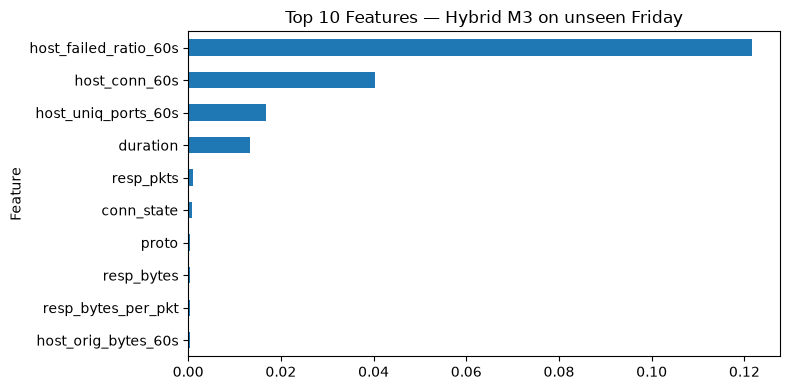

,Feature,F1 drop
16,host_failed_ratio_60s,0.1216
14,host_conn_60s,0.0402
15,host_uniq_ports_60s,0.0167
3,duration,0.0133
9,resp_pkts,0.0010
2,conn_state,0.0009
0,proto,0.0005
5,resp_bytes,0.0005
12,resp_bytes_per_pkt,0.0004
17,host_orig_bytes_60s,0.0003


In [2]:
# Recall per attack type on the CIC day that was left out (= attack types the model never trained on)
per_attack = pd.DataFrame({
    m: {a: v for d in ["cic_tuesday", "cic_wednesday", "cic_thursday", "cic_friday"] for a, v in results[m][d]["recall_by_attack"].items()}
    for m in results
})
per_attack["Flows"] = cic[cic["label"] == 1]["attack_type"].value_counts()
display(per_attack.sort_values("Hybrid M3 (19)"))

# Permutation importance: Friday-left-out hybrid model scored on 25k Friday flows it never saw
fri = cic[cic["source"] == "cic_friday"]
m_fri = fit_zeek_model(pd.concat([cic[cic["source"] != "cic_friday"], uwf_train], ignore_index=True))
sub = fri.sample(n=25_000, random_state=SEED)
imp = permutation_importance(m_fri, sub[ZEEK_HYBRID_FEATURES], sub["label"].to_numpy(dtype=int), n_repeats=3, random_state=SEED, scoring="f1", n_jobs=-1)
imp_df = pd.DataFrame({"Feature": ZEEK_HYBRID_FEATURES, "F1 drop": imp.importances_mean.round(4)}).sort_values("F1 drop", ascending=False)
imp_df.head(10).iloc[::-1].plot(kind="barh", x="Feature", y="F1 drop", figsize=(8, 4), legend=False)
plt.title("Top 10 Features — Hybrid M3 on unseen Friday")
plt.tight_layout()
plt.show()
display(imp_df.head(10))

## 3. Approaches Compared & Known Limitations

| Approach | Pros | Limitations | How CyberShield Handles It |
|---|---|---|---|
| **Pure Per-Flow** *(14 raw Zeek + ratio features)* | Stateless; scores each flow instantly; better on Bot beacons and UWF-Sum25-1. | Host-minute FPR 2.4–6.1% on unseen CIC days; misses new brute-force/DoS/web attacks. | Candidate second opinion next to Hybrid (not built yet). |
| **Pure 60s Host Window** *(1 row = 1 host-minute)* | One alert per host-minute. | Shrinks 500k flows to ~5k rows; blurs a single bad flow into normal browsing. | Replaced by Hybrid (alerts are grouped *after* scoring). |
| **Hybrid `M3`** *(19 features: per-flow + 60s host context)* ⭐ | Lowest FPR; detects the attack types it trained on (DoS, DDoS, scans, FTP & web brute force, XSS) even on new days. | 1. **New attack types mostly missed** (SSH-Patator 0.6%, GoldenEye 4.7%, Bot 5.5%, SQLi 0%, DNS exfil 0%).<br>2. **Busy benign hosts look like attacks** (UNSW FPR 50%).<br>3. **Low-and-slow** activity (<1 probe/min, beacons) doesn't move 60s counts.<br>4. Window stats need the whole minute (buffer ≥60s live), and a burst can be split across two minutes. | 1. Pair ML with **deterministic Zeek rules** in `detection/` and an anomaly baseline trained on the LAN's own benign traffic.<br>2. `allowlist_src_ips` in `score_zeek_flows()` for gateways/proxies.<br>3. Validate the alert tiers (`suspicious ≥ 0.60`, `high ≥ 0.90`) on real LAN traffic before use. |

### Key Takeaways
- **Production artefact:** `models/zeek-hybrid-m3-v1.joblib`, trained on all CIC + UWF via `uv run python -m cybershield.ml.train_zeek`.
- **What it is:** a detector for *known* attack types. It's strong on what it has seen (≥94% on DoS Hulk/Slowhttptest/slowloris, DDoS, PortScan, FTP-Patator, web brute force, XSS, the infiltration scan) and weak on new types.
- **What drives it:** `host_failed_ratio_60s`, `host_conn_60s`, `host_uniq_ports_60s` and `duration`: host behaviour, no IP/port/TTL memorisation. The same features explain the UNSW false alarms: busy, port-diverse benign hosts look like scanners.
- **Next steps:** real-LAN benign week for an honest FPR, an anomaly baseline for new attack types, and the either-model ensemble above.